# Experiment 7: Logical and Probabilistic Reasoning

## Imports

In [11]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 1. Propositional Logic

### Truth Table: Rain → Road Wet

In [12]:
# P = "It rains", Q = "The road is wet", rule: P -> Q
def implies(p, q):
    return (not p) or q

rows = []
for rain, wet in itertools.product([True, False], repeat=2):
    rows.append({
        "Rain (P)": rain,
        "Road Wet (Q)": wet,
        "P → Q": implies(rain, wet),
    })

truth_table = pd.DataFrame(rows)
print(truth_table.to_string(index=False))

 Rain (P)  Road Wet (Q)  P → Q
     True          True   True
     True         False  False
    False          True   True
    False         False   True


### Verification

In [13]:
# P -> Q must be equivalent to (not P) or Q
equivalent = all(
    row["P → Q"] == ((not row["Rain (P)"]) or row["Road Wet (Q)"])
    for _, row in truth_table.iterrows()
)

# P -> Q is False only when P is True and Q is False
only_false = truth_table[~truth_table["P → Q"]]

# Modus ponens: whenever P and (P -> Q) are True, Q must be True
modus_ponens = truth_table[truth_table["Rain (P)"] & truth_table["P → Q"]]

print("Equivalent to (¬P ∨ Q):", equivalent)
print("Only failing case [P, Q]:", only_false[["Rain (P)", "Road Wet (Q)"]].values.tolist())
print("Modus ponens holds:", bool(modus_ponens["Road Wet (Q)"].all()))

assert equivalent and len(only_false) == 1 and modus_ponens["Road Wet (Q)"].all()

Equivalent to (¬P ∨ Q): True
Only failing case [P, Q]: [[True, False]]
Modus ponens holds: True


## 2. First-Order Logic

### Knowledge Base and Inference

In [1]:
# FOL statements:
#   ∀x (Human(x) → Mortal(x))   "All humans are mortal"
#   Human(Socrates)             "Socrates is a human"
facts = {("Human", "Socrates"), ("Dog", "Fido")}
rules = [("Human", "Mortal")]   # (premise predicate, conclusion predicate), applies to every x


def forward_chain(facts, rules):
    # Universal instantiation + modus ponens, repeated until nothing new is derived
    derived = set(facts)
    changed = True
    while changed:
        changed = False
        for premise, conclusion in rules:
            for predicate, individual in list(derived):
                if predicate == premise and (conclusion, individual) not in derived:
                    derived.add((conclusion, individual))
                    changed = True
    return derived


kb = forward_chain(facts, rules)

print("Derived knowledge base:")
for predicate, individual in sorted(kb):
    print(f"  {predicate}({individual})")

print()
print("Is Socrates mortal?", ("Mortal", "Socrates") in kb)
print("Is Fido mortal?    ", ("Mortal", "Fido") in kb)

Derived knowledge base:
  Dog(Fido)
  Human(Socrates)
  Mortal(Socrates)

Is Socrates mortal? True
Is Fido mortal?     False


## 3. Probability of Events

### Dataset

In [15]:
# A = student attended, B = student passed
data = (
    [("Yes", "Pass")] * 10
    + [("Yes", "Fail")] * 2
    + [("No", "Pass")] * 3
    + [("No", "Fail")] * 5
)
df = pd.DataFrame(data, columns=["Attended", "Result"])

print("Total students:", len(df))
print(pd.crosstab(df["Attended"], df["Result"], margins=True))

Total students: 20
Result    Fail  Pass  All
Attended                 
No           5     3    8
Yes          2    10   12
All          7    13   20


### Individual, Joint and Union Probabilities

In [16]:
A = df["Attended"] == "Yes"
B = df["Result"] == "Pass"

P_A = A.mean()
P_B = B.mean()
P_A_and_B = (A & B).mean()    # joint probability
P_A_or_B = (A | B).mean()     # union

print(f"P(A)     = P(Attended)          = {P_A:.4f}")
print(f"P(B)     = P(Passed)            = {P_B:.4f}")
print(f"P(A ∩ B) = P(Attended and Pass) = {P_A_and_B:.4f}")
print(f"P(A ∪ B) = P(Attended or Pass)  = {P_A_or_B:.4f}")

# Verify the addition rule: P(A ∪ B) = P(A) + P(B) - P(A ∩ B)
assert np.isclose(P_A_or_B, P_A + P_B - P_A_and_B)
print("Addition rule verified.")

P(A)     = P(Attended)          = 0.6000
P(B)     = P(Passed)            = 0.6500
P(A ∩ B) = P(Attended and Pass) = 0.5000
P(A ∪ B) = P(Attended or Pass)  = 0.7500
Addition rule verified.


## 4. Conditional Probability

In [17]:
# P(B | A) = P(A ∩ B) / P(A)  -> probability of passing given attendance
P_B_given_A = (A & B).sum() / A.sum()

# P(A | B) = P(A ∩ B) / P(B)  -> probability of attendance given a pass
P_A_given_B = (A & B).sum() / B.sum()

print(f"P(B | A) = P(Pass | Attended) = {P_B_given_A:.4f}")
print(f"P(A | B) = P(Attended | Pass) = {P_A_given_B:.4f}")

# Cross-check with the formula using the probabilities from Exercise 3
assert np.isclose(P_B_given_A, P_A_and_B / P_A)
assert np.isclose(P_A_given_B, P_A_and_B / P_B)

# Compare with the unconditional probability of passing
print(f"\nP(B) = {P_B:.4f} vs P(B | A) = {P_B_given_A:.4f}")

P(B | A) = P(Pass | Attended) = 0.8333
P(A | B) = P(Attended | Pass) = 0.7692

P(B) = 0.6500 vs P(B | A) = 0.8333


## 5. Bayes' Theorem

### Disease Diagnosis

In [18]:
def bayes(prior, sensitivity, false_positive_rate):
    # P(D | +) = P(+ | D) P(D) / P(+)
    p_positive = sensitivity * prior + false_positive_rate * (1 - prior)
    posterior = sensitivity * prior / p_positive
    return posterior, p_positive


prior = 0.01                 # P(Disease)
sensitivity = 0.95           # P(Positive | Disease)
false_positive_rate = 0.05   # P(Positive | No Disease)

posterior, p_positive = bayes(prior, sensitivity, false_positive_rate)

print(f"P(Disease)              = {prior:.4f}")
print(f"P(Positive | Disease)   = {sensitivity:.4f}")
print(f"P(Positive | No Disease)= {false_positive_rate:.4f}")
print(f"P(Positive)             = {p_positive:.4f}")
print(f"P(Disease | Positive)   = {posterior:.4f}")

P(Disease)              = 0.0100
P(Positive | Disease)   = 0.9500
P(Positive | No Disease)= 0.0500
P(Positive)             = 0.0590
P(Disease | Positive)   = 0.1610


## 6. Visualization

### Calculated Probabilities

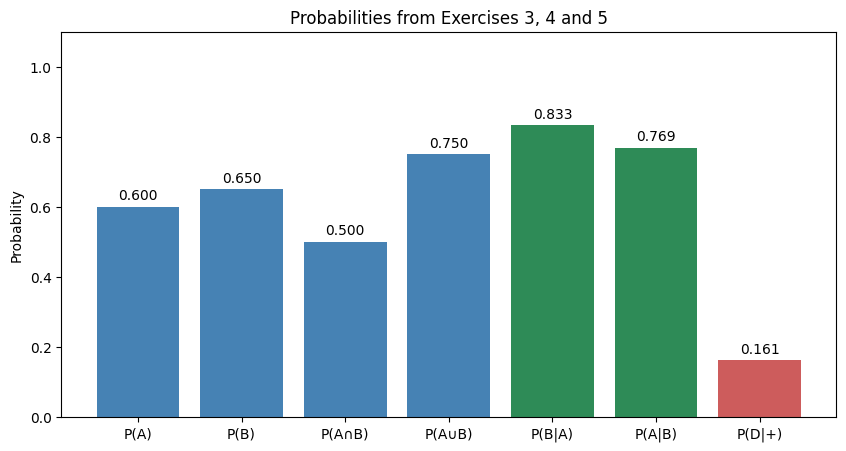

In [19]:
labels = ["P(A)", "P(B)", "P(A∩B)", "P(A∪B)", "P(B|A)", "P(A|B)", "P(D|+)"]
values = [P_A, P_B, P_A_and_B, P_A_or_B, P_B_given_A, P_A_given_B, posterior]
colors = ["steelblue"] * 4 + ["seagreen"] * 2 + ["indianred"]

plt.figure(figsize=(10, 5))
plt.bar(labels, values, color=colors)
for i, v in enumerate(values):
    plt.text(i, v + 0.02, f"{v:.3f}", ha="center")
plt.ylim(0, 1.1)
plt.ylabel("Probability")
plt.title("Probabilities from Exercises 3, 4 and 5")
plt.show()

### Effect of Changing the Prior

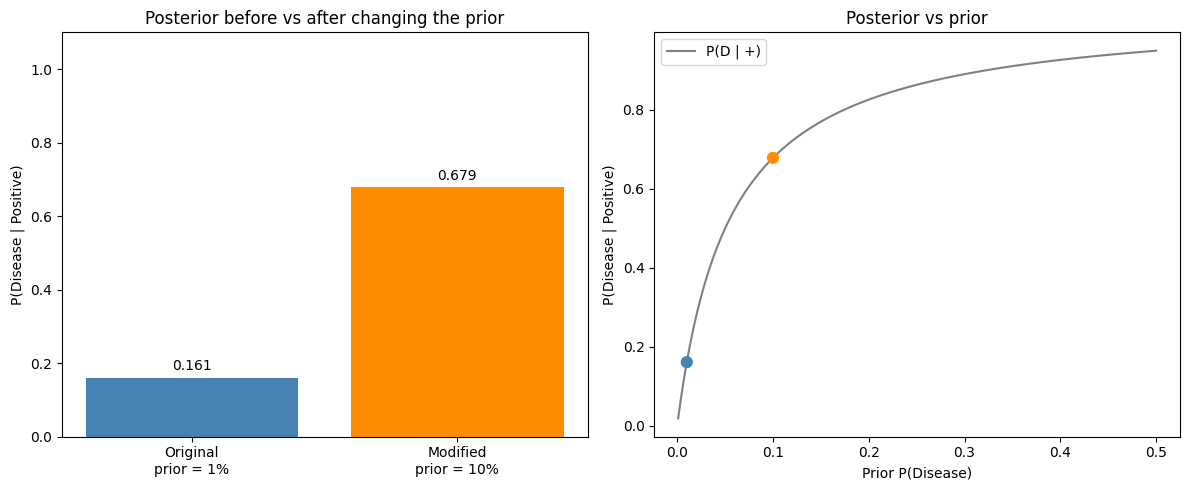

Prior 1% -> posterior 0.1610
Prior 10% -> posterior 0.6786


In [20]:
# Modify one input: disease prevalence (prior) from 1% to 10%
modified_prior = 0.10
post_mod, p_pos_mod = bayes(modified_prior, sensitivity, false_positive_rate)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Left: posterior before vs after changing the prior
names = [f"Original\nprior = {prior:.0%}", f"Modified\nprior = {modified_prior:.0%}"]
posts_two = [posterior, post_mod]
axes[0].bar(names, posts_two, color=["steelblue", "darkorange"])
for i, v in enumerate(posts_two):
    axes[0].text(i, v + 0.02, f"{v:.3f}", ha="center")
axes[0].set_ylim(0, 1.1)
axes[0].set_ylabel("P(Disease | Positive)")
axes[0].set_title("Posterior before vs after changing the prior")

# Right: posterior as a function of the prior
priors = np.linspace(0.001, 0.5, 200)
curve = [bayes(p, sensitivity, false_positive_rate)[0] for p in priors]
axes[1].plot(priors, curve, color="gray", label="P(D | +)")
axes[1].scatter([prior, modified_prior], posts_two, color=["steelblue", "darkorange"], zorder=3, s=60)
axes[1].set_xlabel("Prior P(Disease)")
axes[1].set_ylabel("P(Disease | Positive)")
axes[1].set_title("Posterior vs prior")
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"Prior {prior:.0%} -> posterior {posterior:.4f}")
print(f"Prior {modified_prior:.0%} -> posterior {post_mod:.4f}")